## 19 Acceleration, Braking, and GPS Exceptions (Flag 19)

### Dataset Overview
A constructed WorldTrace case with 180 trajectories. Geometry source: Observed map-matched NYC WorldTrace road paths or continuous road-aligned return traversals. Environmental, temporal, mode, vehicle, and event attributes are arranged to make all stated comparisons measurable without changing the route coordinates used by the figures.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Investigate acceleration, braking behavior and special cases across the provided trajectories.

Role: Urban mobility analyst


Category: Spatial braking clusters and positioning-error exceptions

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

Load the libraries used below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

Load the primary and supporting point tables.

In [ ]:
dataset_path='trajectories.csv'
df=pd.read_csv(dataset_path,low_memory=False)
df['departure_time']=pd.to_datetime(df.departure_time)
df['arrival_time']=pd.to_datetime(df.arrival_time)

In [ ]:
user_dataset_path='trajectory_points.csv'
user_df=pd.read_csv(user_dataset_path,low_memory=False)

### **Question 1**: Where are braking events located, and what share falls in the recurrent city clusters?

#### Analysis action

Count braking events by spatial cluster and inspect their mapped locations.

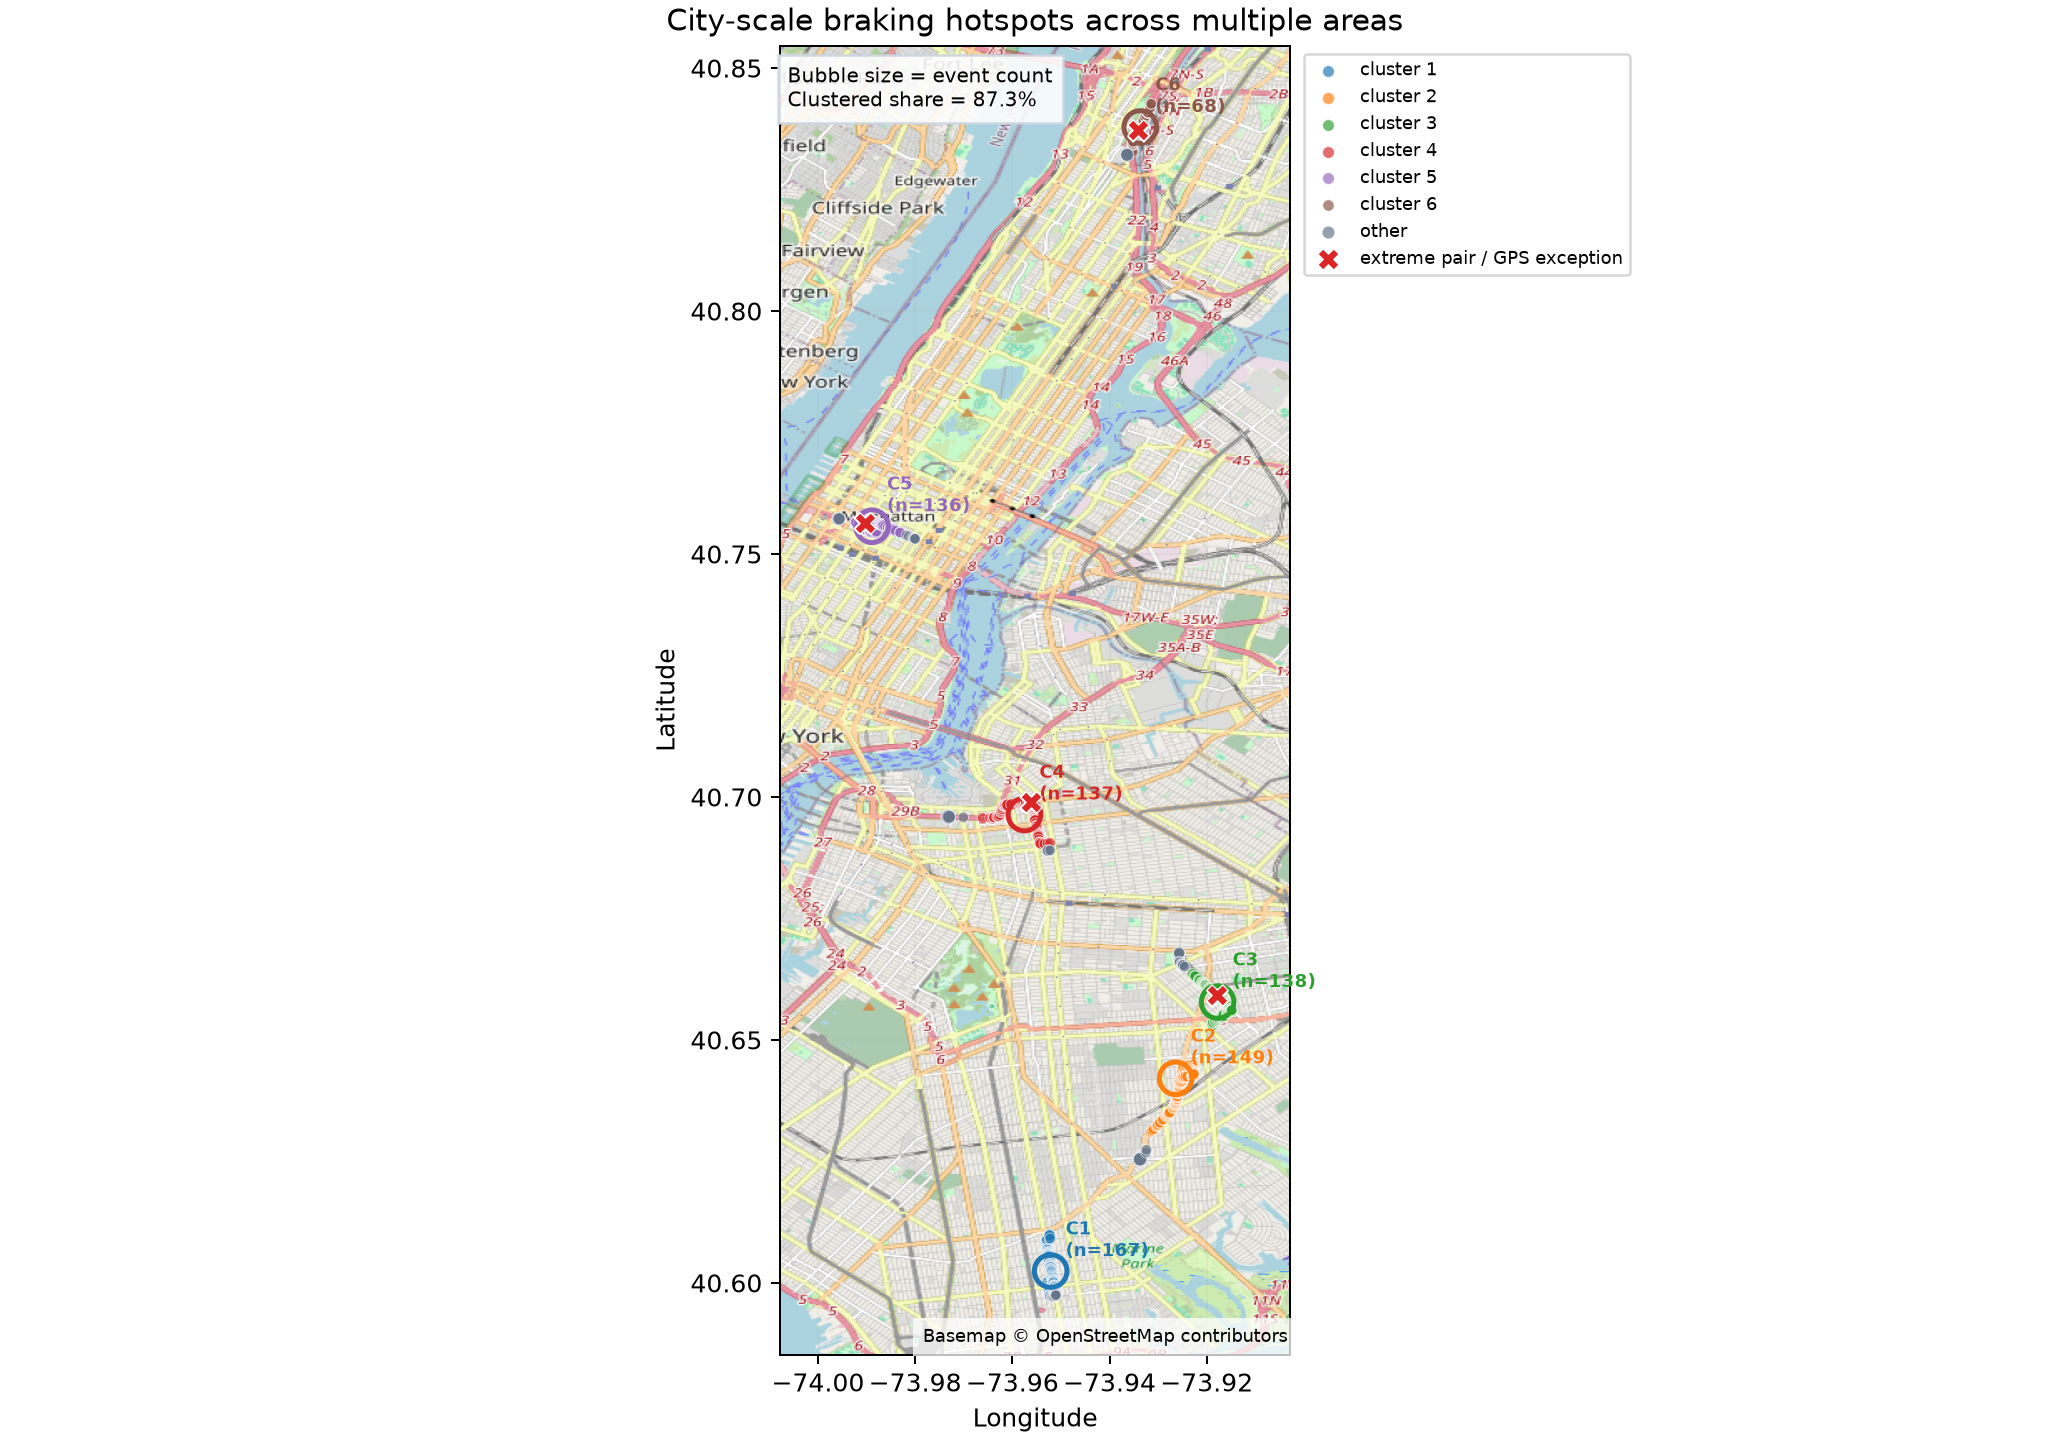

In [ ]:
b=user_df[user_df.event_type.isin(['braking','extreme_brake'])]; print(b.braking_zone.value_counts()); print('clustered share',b.braking_zone.str.startswith('cluster').mean()); b.braking_zone.value_counts().plot.bar(); plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex19_insight_1",
  "insight": "Braking events are spatially concentrated in several parts of the city.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Acceleration, Braking, and GPS Exceptions: Insight 1",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Where are braking events located, and what share falls in the recurrent city clusters?",
  "actionable_insight": "Count braking events by spatial cluster and inspect their mapped locations.",
  "code": "b=user_df[user_df.event_type.isin(['braking','extreme_brake'])]; print(b.braking_zone.value_counts()); print('clustered share',b.braking_zone.str.startswith('cluster').mean()); b.braking_zone.value_counts().plot.bar(); plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 2**: How does braking frequency change across the observed speed range?

#### Analysis action

Relate every trajectory's braking rate to its realized mean speed, then trace the approximate relationship using five-kilometer-per-hour speed bins rather than only a low/high split.

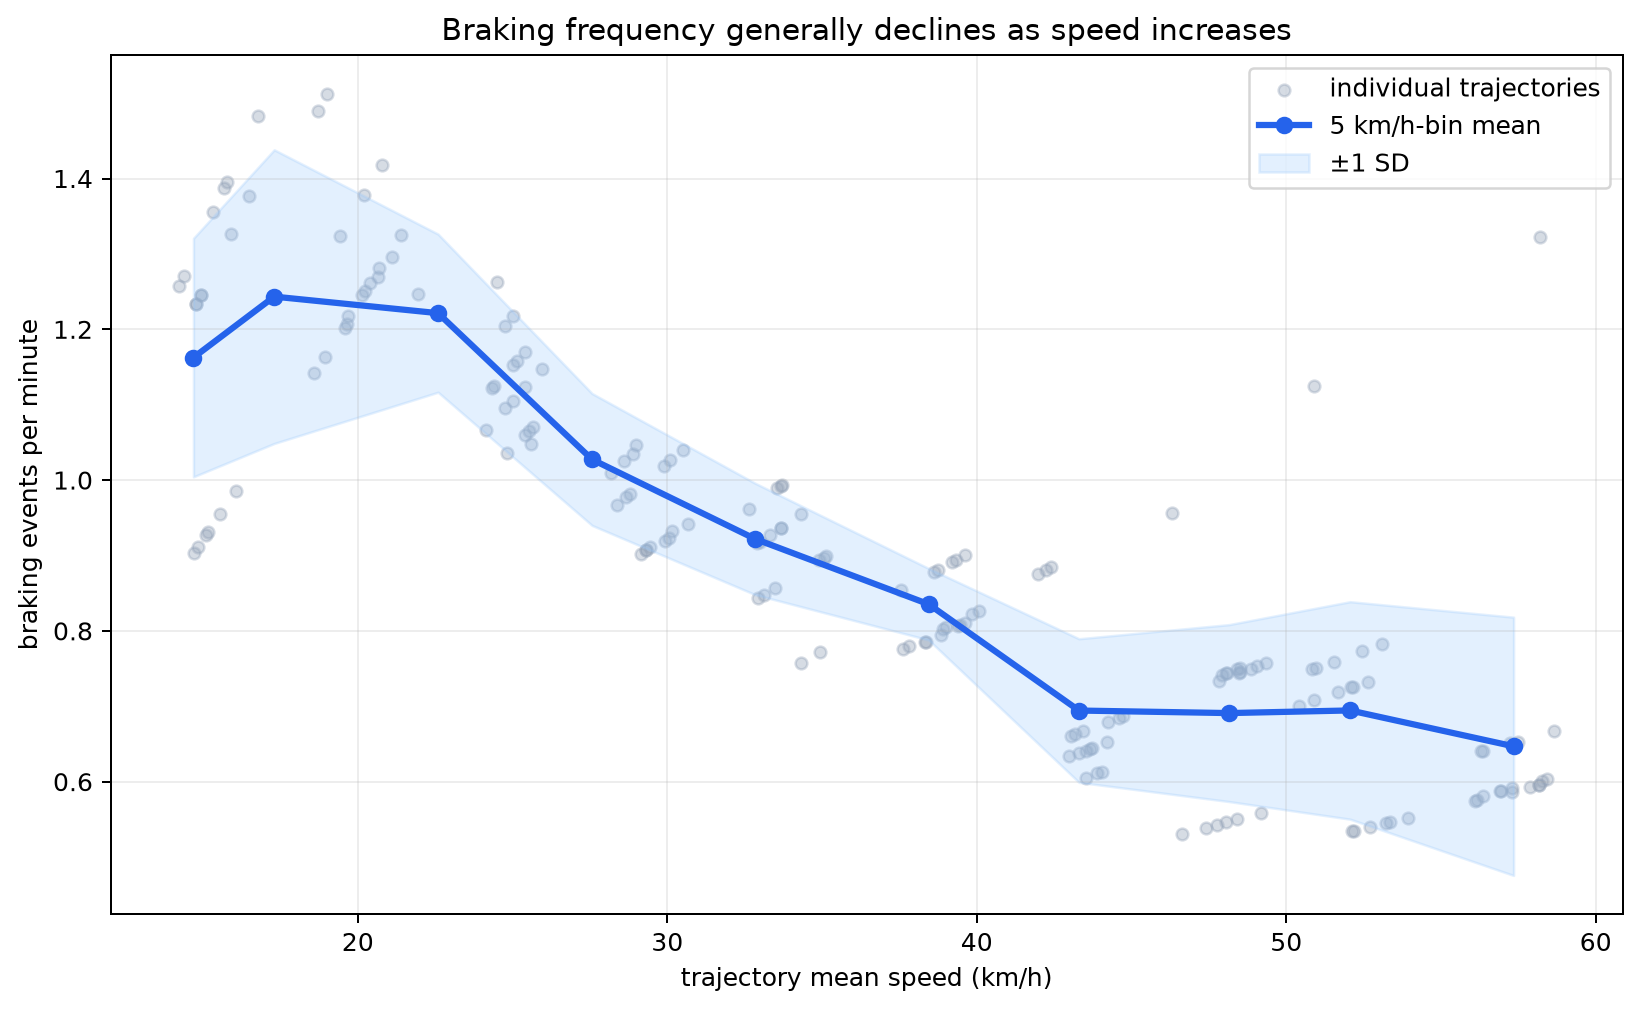

In [ ]:
x=df[['trajectory_id','mean_speed_kmh','braking_frequency_per_min']].copy();edges=np.arange(10,66,5);x['speed_bin']=pd.cut(x.mean_speed_kmh,edges,include_lowest=True);g=x.groupby('speed_bin',observed=True).agg(speed=('mean_speed_kmh','mean'),frequency=('braking_frequency_per_min','mean'),frequency_sd=('braking_frequency_per_min','std'),trajectories=('trajectory_id','size')).reset_index(drop=True)
print(g.round(3));print('speed-frequency correlation',round(x.mean_speed_kmh.corr(x.braking_frequency_per_min),3));print('coarse regime check');print(df.groupby('speed_regime').agg(speed=('mean_speed_kmh','mean'),frequency=('braking_frequency_per_min','mean')).round(3))
fig,ax=plt.subplots(figsize=(9,5.5),constrained_layout=True);ax.scatter(x.mean_speed_kmh,x.braking_frequency_per_min,s=22,color='#94a3b8',alpha=.38,label='individual trajectories');ax.plot(g.speed,g.frequency,color='#2563eb',marker='o',linewidth=2.5,label='5 km/h-bin mean');ax.fill_between(g.speed,(g.frequency-g.frequency_sd).clip(lower=0),g.frequency+g.frequency_sd,color='#93c5fd',alpha=.25,label='±1 SD');ax.set(title='Braking frequency generally declines as speed increases',xlabel='trajectory mean speed (km/h)',ylabel='braking events per minute');ax.grid(alpha=.22);ax.legend();plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex19_insight_2",
  "insight": "Braking occurs more frequently during lower-speed periods than during sustained high-speed movement.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Acceleration, Braking, and GPS Exceptions: Insight 2",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "How does braking frequency change across the observed speed range?",
  "actionable_insight": "Relate every trajectory's braking rate to its realized mean speed, then trace the approximate relationship using five-kilometer-per-hour speed bins rather than only a low/high split.",
  "code": "x=df[['trajectory_id','mean_speed_kmh','braking_frequency_per_min']].copy();edges=np.arange(10,66,5);x['speed_bin']=pd.cut(x.mean_speed_kmh,edges,include_lowest=True);g=x.groupby('speed_bin',observed=True).agg(speed=('mean_speed_kmh','mean'),frequency=('braking_frequency_per_min','mean'),frequency_sd=('braking_frequency_per_min','std'),trajectories=('trajectory_id','size')).reset_index(drop=True)\nprint(g.round(3));print('speed-frequency correlation',round(x.mean_speed_kmh.corr(x.braking_frequency_per_min),3));print('coarse regime check');print(df.groupby('speed_regime').agg(speed=('mean_speed_kmh','mean'),frequency=('braking_frequency_per_min','mean')).round(3))\nfig,ax=plt.subplots(figsize=(9,5.5),constrained_layout=True);ax.scatter(x.mean_speed_kmh,x.braking_frequency_per_min,s=22,color='#94a3b8',alpha=.38,label='individual trajectories');ax.plot(g.speed,g.frequency,color='#2563eb',marker='o',linewidth=2.5,label='5 km/h-bin mean');ax.fill_between(g.speed,(g.frequency-g.frequency_sd).clip(lower=0),g.frequency+g.frequency_sd,color='#93c5fd',alpha=.25,label='±1 SD');ax.set(title='Braking frequency generally declines as speed increases',xlabel='trajectory mean speed (km/h)',ylabel='braking events per minute');ax.grid(alpha=.22);ax.legend();plt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: Which trajectories have braking followed by acceleration within five seconds, and which contain braking without a following acceleration?

#### Analysis action

Separate trajectories with short brake–acceleration pairs from braking-only trajectories, then inspect the complete event-level interval distribution.

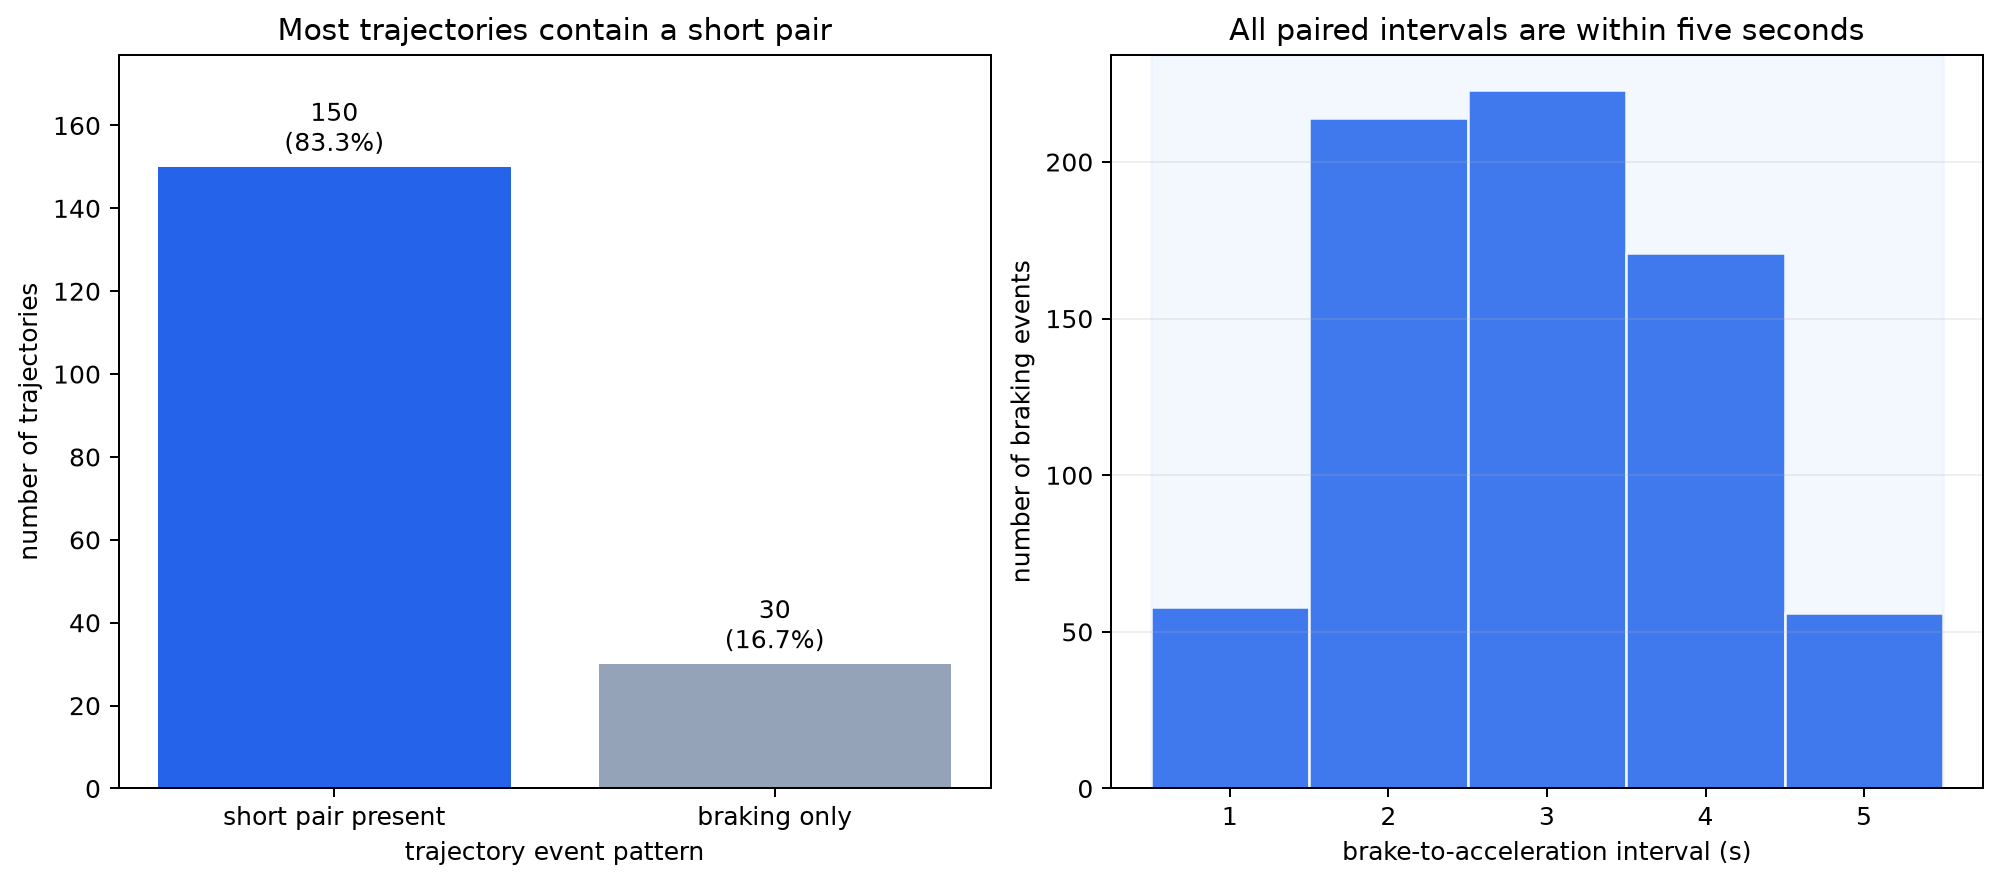

In [ ]:
brakes=user_df[user_df.event_type.eq('braking')].copy();paired=brakes[pd.to_numeric(brakes.seconds_to_following_acceleration,errors='coerce').notna()].copy();paired['interval_s']=pd.to_numeric(paired.seconds_to_following_acceleration)
paired_ids=set(paired.trajectory_id);status=pd.Series(np.where(df.trajectory_id.isin(paired_ids),'short pair present','braking only'),index=df.trajectory_id)
counts=status.value_counts().reindex(['short pair present','braking only']);print(counts);print('paired trajectory share',round(counts.iloc[0]/len(df),3));print('braking-only trajectory IDs');print(df.loc[~df.trajectory_id.isin(paired_ids),'trajectory_id'].tolist());print(paired.interval_s.describe())
fig,ax=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True);colors=['#2563eb','#94a3b8'];bars=ax[0].bar(counts.index,counts.values,color=colors);ax[0].bar_label(bars,labels=[f'{v}\n({v/len(df):.1%})' for v in counts.values],padding=3);ax[0].set(title='Most trajectories contain a short pair',xlabel='trajectory event pattern',ylabel='number of trajectories');ax[0].set_ylim(0,max(counts)*1.18)
bins=np.arange(.5,6.5,1);ax[1].hist(paired.interval_s,bins=bins,color='#2563eb',edgecolor='white');ax[1].set_xticks(range(1,6));ax[1].axvspan(.5,5.5,color='#bfdbfe',alpha=.18);ax[1].set(title='All paired intervals are within five seconds',xlabel='brake-to-acceleration interval (s)',ylabel='number of braking events');ax[1].grid(axis='y',alpha=.2);plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex19_insight_3",
  "insight": "Most trajectories contain braking-acceleration events within short intervals, not only braking without acceleration.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Acceleration, Braking, and GPS Exceptions: Insight 3",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Which trajectories have braking followed by acceleration within five seconds, and which contain braking without a following acceleration?",
  "actionable_insight": "Separate trajectories with short brake–acceleration pairs from braking-only trajectories, then inspect the complete event-level interval distribution.",
  "code": "brakes=user_df[user_df.event_type.eq('braking')].copy();paired=brakes[pd.to_numeric(brakes.seconds_to_following_acceleration,errors='coerce').notna()].copy();paired['interval_s']=pd.to_numeric(paired.seconds_to_following_acceleration)\npaired_ids=set(paired.trajectory_id);status=pd.Series(np.where(df.trajectory_id.isin(paired_ids),'short pair present','braking only'),index=df.trajectory_id)\ncounts=status.value_counts().reindex(['short pair present','braking only']);print(counts);print('paired trajectory share',round(counts.iloc[0]/len(df),3));print('braking-only trajectory IDs');print(df.loc[~df.trajectory_id.isin(paired_ids),'trajectory_id'].tolist());print(paired.interval_s.describe())\nfig,ax=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True);colors=['#2563eb','#94a3b8'];bars=ax[0].bar(counts.index,counts.values,color=colors);ax[0].bar_label(bars,labels=[f'{v}\\n({v/len(df):.1%})' for v in counts.values],padding=3);ax[0].set(title='Most trajectories contain a short pair',xlabel='trajectory event pattern',ylabel='number of trajectories');ax[0].set_ylim(0,max(counts)*1.18)\nbins=np.arange(.5,6.5,1);ax[1].hist(paired.interval_s,bins=bins,color='#2563eb',edgecolor='white');ax[1].set_xticks(range(1,6));ax[1].axvspan(.5,5.5,color='#bfdbfe',alpha=.18);ax[1].set(title='All paired intervals are within five seconds',xlabel='brake-to-acceleration interval (s)',ylabel='number of braking events');ax[1].grid(axis='y',alpha=.2);plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 4**: Which trajectories contain co-located extreme acceleration/braking and abnormal GPS offsets?

#### Analysis action

Plot point-level GPS-to-road offset and speed profiles for the flagged trajectories, and compare them with the ordinary-trajectory median profile.

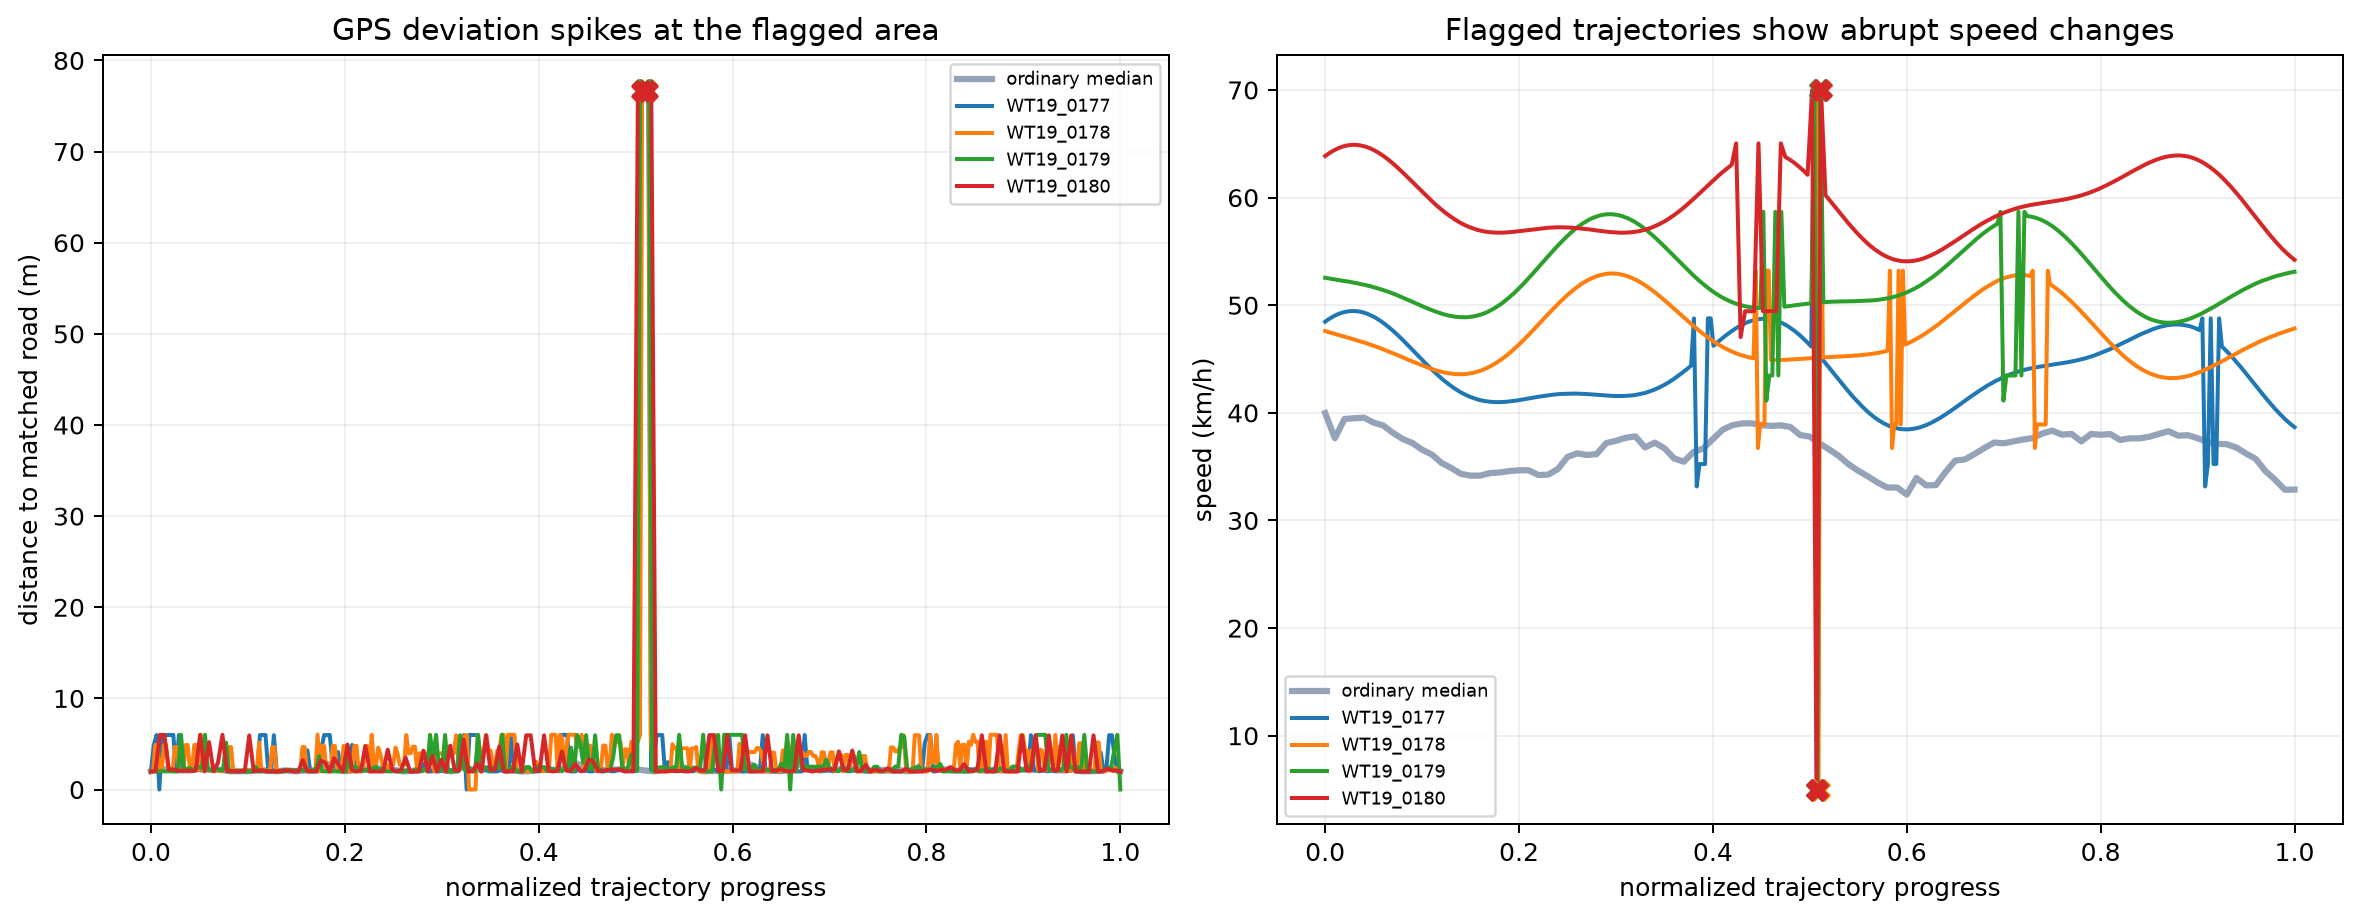

In [ ]:
q=user_df.merge(df[['trajectory_id','is_gps_exception']],on='trajectory_id',how='left');q['progress']=q.point_index/q.groupby('trajectory_id').point_index.transform('max').clip(lower=1)
ordinary=q[~q.is_gps_exception].copy();ordinary['progress_bin']=(ordinary.progress*100).round().astype(int);baseline=ordinary.groupby('progress_bin').agg(offset=('distance_to_matched_road_m','median'),speed=('speed_kmh','median')).reset_index();baseline['progress']=baseline.progress_bin/100
bad=q[q.is_gps_exception].copy();print('Flagged trajectories');print(df.loc[df.is_gps_exception,['trajectory_id','mean_gps_road_offset_m','mean_speed_kmh']]);print('Extreme points');print(bad[bad.event_type.str.startswith('extreme')][['trajectory_id','event_type','speed_kmh','acceleration_mps2','distance_to_matched_road_m']])
fig,ax=plt.subplots(1,2,figsize=(13,5),constrained_layout=True);colors=plt.get_cmap('tab10').colors
ax[0].plot(baseline.progress,baseline.offset,color='#94a3b8',linewidth=2.5,label='ordinary median')
ax[1].plot(baseline.progress,baseline.speed,color='#94a3b8',linewidth=2.5,label='ordinary median')
for j,(tid,g) in enumerate(bad.sort_values('point_index').groupby('trajectory_id')):
    color=colors[j];ax[0].plot(g.progress,g.distance_to_matched_road_m,color=color,linewidth=1.6,label=tid);ax[1].plot(g.progress,g.speed_kmh,color=color,linewidth=1.6,label=tid)
    extreme=g[g.event_type.str.startswith('extreme')];ax[0].scatter(extreme.progress,extreme.distance_to_matched_road_m,color=color,marker='X',s=65,zorder=5);ax[1].scatter(extreme.progress,extreme.speed_kmh,color=color,marker='X',s=65,zorder=5)
ax[0].set(title='GPS deviation spikes at the flagged area',xlabel='normalized trajectory progress',ylabel='distance to matched road (m)');ax[0].grid(alpha=.2);ax[0].legend(fontsize=7)
ax[1].set(title='Flagged trajectories show abrupt speed changes',xlabel='normalized trajectory progress',ylabel='speed (km/h)');ax[1].grid(alpha=.2);ax[1].legend(fontsize=7);plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_4.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex19_insight_4",
  "insight": "A few trajectories show extreme acceleration and braking within the same area, suggesting possible GPS positioning errors.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_4.png"
    ],
    "title": "Acceleration, Braking, and GPS Exceptions: Insight 4",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Which trajectories contain co-located extreme acceleration/braking and abnormal GPS offsets?",
  "actionable_insight": "Plot point-level GPS-to-road offset and speed profiles for the flagged trajectories, and compare them with the ordinary-trajectory median profile.",
  "code": "q=user_df.merge(df[['trajectory_id','is_gps_exception']],on='trajectory_id',how='left');q['progress']=q.point_index/q.groupby('trajectory_id').point_index.transform('max').clip(lower=1)\nordinary=q[~q.is_gps_exception].copy();ordinary['progress_bin']=(ordinary.progress*100).round().astype(int);baseline=ordinary.groupby('progress_bin').agg(offset=('distance_to_matched_road_m','median'),speed=('speed_kmh','median')).reset_index();baseline['progress']=baseline.progress_bin/100\nbad=q[q.is_gps_exception].copy();print('Flagged trajectories');print(df.loc[df.is_gps_exception,['trajectory_id','mean_gps_road_offset_m','mean_speed_kmh']]);print('Extreme points');print(bad[bad.event_type.str.startswith('extreme')][['trajectory_id','event_type','speed_kmh','acceleration_mps2','distance_to_matched_road_m']])\nfig,ax=plt.subplots(1,2,figsize=(13,5),constrained_layout=True);colors=plt.get_cmap('tab10').colors\nax[0].plot(baseline.progress,baseline.offset,color='#94a3b8',linewidth=2.5,label='ordinary median')\nax[1].plot(baseline.progress,baseline.speed,color='#94a3b8',linewidth=2.5,label='ordinary median')\nfor j,(tid,g) in enumerate(bad.sort_values('point_index').groupby('trajectory_id')):\n    color=colors[j];ax[0].plot(g.progress,g.distance_to_matched_road_m,color=color,linewidth=1.6,label=tid);ax[1].plot(g.progress,g.speed_kmh,color=color,linewidth=1.6,label=tid)\n    extreme=g[g.event_type.str.startswith('extreme')];ax[0].scatter(extreme.progress,extreme.distance_to_matched_road_m,color=color,marker='X',s=65,zorder=5);ax[1].scatter(extreme.progress,extreme.speed_kmh,color=color,marker='X',s=65,zorder=5)\nax[0].set(title='GPS deviation spikes at the flagged area',xlabel='normalized trajectory progress',ylabel='distance to matched road (m)');ax[0].grid(alpha=.2);ax[0].legend(fontsize=7)\nax[1].set(title='Flagged trajectories show abrupt speed changes',xlabel='normalized trajectory progress',ylabel='speed (km/h)');ax[1].grid(alpha=.2);ax[1].legend(fontsize=7);plt.show()",
  "insight_type": "exception_deviation",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "matched_road_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 19)

Braking events are spatially concentrated in several parts of the city. Braking occurs more frequently during lower-speed periods than during sustained high-speed movement. Most trajectories contain braking-acceleration events within short intervals, not only braking without acceleration. A few trajectories show extreme acceleration and braking within the same area, suggesting possible GPS positioning errors.